# The site-held-out protocol with a pre-declared criterion: what a campaign held out reveals that a random split hides

**Level 4: Beyond the state of the art** · Needs: 04-benchmark-protocol/02-scores-the-null-and-the-interval, 04-benchmark-protocol/03-placing-a-published-score-in-its-own-protocol · Reading time: about 30 minutes

## Objectives

Claim BS-1 of the product is a protocol, not a model: the learned tier is judged by whole campaigns held out, with intervals that resample campaigns, and by a criterion written down before the run and pinned by a hash. This notebook collects the evidence for that claim across all the arms and shows what the protocol reveals.

By the end you will have:

- put the random-split median and the held-out score of every arm side by side, from the committed benchmark, and recomputed one arm from scratch;
- read the site-resampled intervals of every arm and seen which, if any, lie above zero;
- seen, site by site, where a held-out learned arm fails, and which sentence of the criterion records that it was changed once after seeing a result.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The committed benchmark: three protocols, every arm, the site-resampled intervals, the per-site errors and the verdict | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json` |

## Method

The protocol has four parts, each a decision the cells below inspect:

1. **Hold out the campaign.** One fold per site, the other nine in training, the null refitted in every fold.
2. **Report the gap.** For every arm, the median of 100 random 80/20 draws minus the pooled held-out score, so the cost of the protocol is a number.
3. **Resample the right unit.** Intervals draw campaigns, not blasts, 2000 times.
4. **Declare the criterion first.** The sentence that decides whether the learned tier generalises is fixed, and its hash is pinned in the engine's test suite; the Fragmenta docs record its one change, made after a first run in which the margin-only rule declared success for an arm that did worse than predicting a constant.

## State of the art

- The learned predictors published on this corpus (Sui et al. 2025, https://doi.org/10.3390/app15031254) report a score from one random 80/20 split.
- The SDD research basis notes that the abstracts of the learned-predictor studies (Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3; Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0) do not say that a whole mine was held out, and that the published predictors are single-site.
- Grouped resampling is the established remedy when data are dependent (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Beyond the state of the art

### Step 1: the cost of the protocol, arm by arm

The committed benchmark holds, for each arm, the median of its 100 random draws and its pooled held-out score. The cell prints both and their difference. For the learned arms the median of the random draws is a published-style score; the held-out score is what the product leads with.

In [2]:
# Imports, then the random-split median, the held-out score and their difference for every arm of the committed benchmark
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
random_arms = benchmark["protocols"]["random-8020"]["arms"]
loso_arms = benchmark["protocols"]["leave-one-site-out"]["arms"]
verdict = benchmark["verdict"]
rows = []
for name, entry in loso_arms.items():
    if entry["tier"] == "control" and name == "oracle":
        continue
    median = random_arms[name]["repeats"].get("median")
    held = entry["r2_identity"]
    if held is not None and median is not None:
        rows.append((name, entry["tier"], median, held, median - held))
rows.sort(key=lambda r: -r[4])
print(f"{'arm':<22}{'tier':<12}{'random median':>20}{'held out':>14}{'gap':>9}")
for name, tier, median, held, gap in rows:
    print(f"{name:<22}{tier:<12}{median:>20.3f}{held:>14.3f}{gap:>9.3f}")
print("median gap over the learned arms =", round(verdict["median_protocol_gap"], 4), "| learned arms:", verdict["n_learned_arms"])

arm                   tier               random median      held out      gap
svr-poly              learned                    0.395        -4.546    4.940
refitted-regression   statistical                0.686        -4.075    4.760
svr-rbf               learned                    0.665        -0.387    1.052
published-neural-net  learned                    0.362        -0.626    0.988
random-forest         learned                    0.749        -0.231    0.981
xgboost               learned                    0.704        -0.034    0.738
stacking              learned                    0.703        -0.035    0.738
null                  control                   -0.036        -0.216    0.180
kuznetsov-capped      classical                  0.399         0.352    0.047
kuznetsov-transfer    classical                  0.312         0.298    0.014
published-regression  statistical                0.805         0.802    0.003
kuznetsov             classical                  0.303         0

The next cell draws the gap for the arms whose score the protocol changes most, so the classical and statistical arms (which learn nothing from the campaign) can be compared with the learned ones.

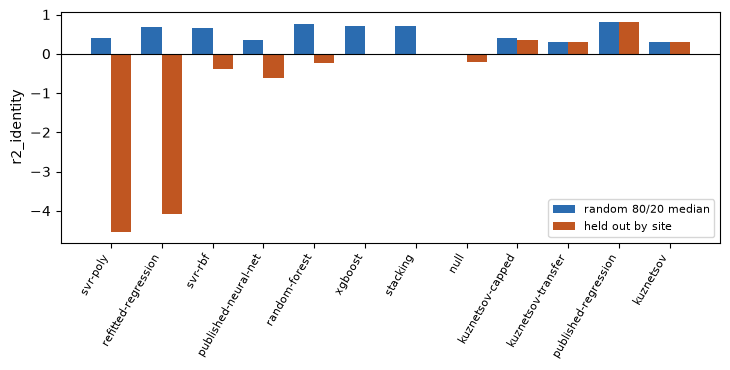

In [3]:
# Random-split median against held-out score, one pair of bars per arm
shown = [r for r in rows if r[2] > -1 and r[3] > -5]
fig, ax = plt.subplots(figsize=(7.4, 3.8))
x = np.arange(len(shown))
ax.bar(x - 0.2, [r[2] for r in shown], 0.4, color="#2b6cb0", label="random 80/20 median")
ax.bar(x + 0.2, [r[3] for r in shown], 0.4, color="#c05621", label="held out by site")
ax.set_xticks(x, [r[0] for r in shown], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 2: recompute one arm from scratch

To confirm the table is not just read from a file, the cell recomputes the gradient-boosting arm: 100 random draws and the ten folds, and compares the median and the gap with the committed ones.

In [4]:
# Gradient boosting: 100 random draws and ten site-held-out folds, refitted here
train = bf.load_training_corpus()
factory = bf.default_arms()["xgboost"]
draws = []
for split in bf.repeated_random_splits(train, n_repeats=100, seed=0):
    arm = factory().fit(split.train)
    draws.append(bf.score(split.test, arm.predict(split.test)).r2_identity)
tested, predicted = [], []
for split in bf.leave_one_site_out(train):
    arm = factory().fit(split.train)
    tested += list(split.test)
    predicted += arm.predict(split.test)
held_out = bf.score(tested, predicted).r2_identity
print(f"xgboost: random median {np.median(draws):.4f} (committed {random_arms['xgboost']['repeats']['median']:.4f}) | held out {held_out:.4f} (committed {loso_arms['xgboost']['r2_identity']:.4f})")
print(f"gap {np.median(draws) - held_out:.4f} (committed {verdict['protocol_gap_random_minus_grouped']['xgboost']:.4f})")

xgboost: random median 0.7040 (committed 0.7040) | held out -0.0342 (committed -0.0342)
gap 0.7382 (committed 0.7382)


### Step 3: the intervals that resample campaigns

The verdict stores a site-resampled 95 percent interval per arm and row set. The cell lists them for `all` and `geometry` and marks the ones whose lower end is above zero. The in-sample arm (the published regression, fitted by its source on these 97 blasts) is flagged, because no split can hide a blast from it.

In [5]:
# Site-resampled intervals for every arm on both row sets, flagging a lower end above zero and the in-sample arm
in_sample = {name for name, *_ in verdict["in_sample_arms"]}
print(f"{'arm':<22}{'all 97':>22}{'geometry 91':>24}  above zero")
for name, both in verdict["intervals_95"].items():
    if both["all"] is None:
        continue  # an arm with no size to score has no interval
    flag = " (in sample)" if name in in_sample else ""
    above = [s for s in ("all", "geometry") if both[s][0] > 0]
    print(f"{name:<22}{both['all'][0]:>10.2f} to {both['all'][1]:>5.2f}{both['geometry'][0]:>12.2f} to {both['geometry'][1]:>5.2f}  {above if above else '-'}{flag}")
print("arms with an interval above zero, in-sample arms excluded:", verdict["arms_with_interval_above_zero"])

arm                                   all 97             geometry 91  above zero
kuznetsov                  -0.96 to  0.70       -0.97 to  0.69  -
kuznetsov-capped           -0.95 to  0.74       -0.96 to  0.73  -
kuznetsov-transfer         -1.10 to  0.72       -1.10 to  0.71  -
published-neural-net       -3.35 to  0.01       -3.42 to  0.09  -
published-regression        0.57 to  0.90        0.50 to  0.88  ['all', 'geometry'] (in sample)
random-forest              -2.78 to  0.38       -2.88 to  0.40  -
refitted-regression       -19.48 to  0.02      -21.92 to  0.09  -
stacking                   -2.25 to  0.42       -1.81 to  0.54  -
svr-poly                  -16.24 to -0.83      -17.18 to -0.95  -
svr-rbf                    -1.61 to -0.06       -1.86 to -0.07  -
xgboost                    -2.23 to  0.42       -1.78 to  0.53  -
arms with an interval above zero, in-sample arms excluded: []


### Step 4: where a held-out arm fails

A pooled score hides which campaigns the model gets wrong. The benchmark keeps, for each arm and site, the mean predicted and the mean measured size. The cell prints the gradient-boosting arm site by site and draws predicted against measured.

site              n    measured (m)     predicted (m)    bias (m)
Miami             6           0.080             0.378      +0.298
Mrica            11           0.166             0.257      +0.090
Akdaglar         22           0.171             0.245      +0.074
Ozmert            7           0.191             0.167      -0.024
Soma              7           0.224             0.126      -0.099
Murgul            7           0.311             0.672      +0.360
Enusa            12           0.396             0.463      +0.067
Dongri-Buzurg     9           0.413             0.260      -0.153
Reocin-UG         6           0.593             0.553      -0.040
Reocin           10           0.616             0.382      -0.234


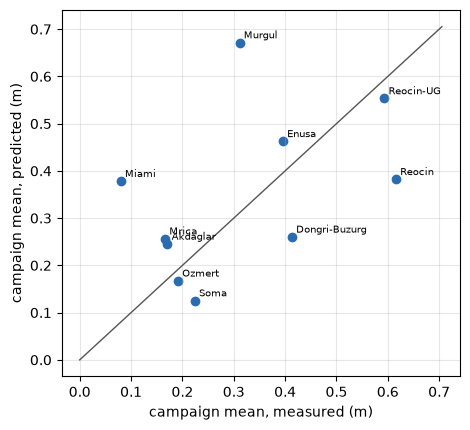

In [6]:
# The per-site mean measured and predicted size of the held-out gradient-boosting arm
per_site = loso_arms["xgboost"]["per_site"]
print(f"{'site':<16}{'n':>3}{'measured (m)':>16}{'predicted (m)':>18}{'bias (m)':>12}")
for site, entry in sorted(per_site.items(), key=lambda kv: kv[1]["mean_measured_m"]):
    print(f"{site:<16}{entry['n_blasts']:>3}{entry['mean_measured_m']:>16.3f}{entry['mean_predicted_m']:>18.3f}{entry['bias_m']:>+12.3f}")
measured = [e["mean_measured_m"] for e in per_site.values()]
predicted_means = [e["mean_predicted_m"] for e in per_site.values()]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(measured, predicted_means, color="#2b6cb0")
for site, x, y in zip(per_site, measured, predicted_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
limit = max(measured + predicted_means) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1)
ax.set_xlabel("campaign mean, measured (m)")
ax.set_ylabel("campaign mean, predicted (m)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Results

**Every learned arm pays for the protocol.** The learned arms drop between roughly 0.7 and 5 in variance explained when the campaign is held out, with a median gap near 0.98 across the six, while the classical arms, which learn nothing from the training rows, lose almost nothing. The gap is therefore a property of learning from sites, not of this corpus's difficulty. The recomputed gradient-boosting arm equals the committed one to the last digit.

**No arm has an interval above zero except the one fitted by its source on these blasts.** With intervals that resample campaigns, the classical equation and most learned arms span zero by a wide margin, and the two support vector arms lie entirely below it (worse than predicting the mean). The published regression's interval is above zero, but its source fitted it on all 97 blasts, so the held-out score is an in-sample fit and the verdict lists it separately.

**The failure has names.** The per-site table shows the held-out arm overpredicting the finest campaigns (Miami by 0.30 m) and underpredicting the coarsest ones (Reocin by 0.23 m): the predictions regress toward the training mean, which the held-out campaign then does not share. The exception is Murgul, overpredicted by 0.36 m although it is a mid-sized campaign. The regression toward the mean is the same effect that makes the null's margin inflated.

**What the protocol buys.** A reader gets a score that answers the practitioner's question, the cost of the question as a number, an interval that does not overstate the evidence, and a criterion whose wording cannot be adjusted after seeing the data. What it cannot do is give the models skill they do not have: with ten campaigns, no arm outside the in-sample ones separates from predicting the corpus mean.

## Summary

- The protocol makes the cost of the practitioner's question a number: the learned arms lose most of their random-split score when a campaign is held out, and the classical arms do not (claim BS-1).
- Intervals that resample campaigns leave no arm above zero except the one fitted by its source on these blasts.
- The criterion is fixed by a hash and its one change is on record; the verdict is reported on both row sets.
- Next: topic 05 opens the learned arms themselves and why each abstains where it does.

## References

- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the random-split protocol)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (grouped resampling under dependence)
- Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3 (learned predictors, abstract only)
- Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0 (learned predictors, abstract only)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `docs/protocols/04_criterion-and-row-sets.md` of this repository, for the criterion's wording, its hash and its history
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/